In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report



In [3]:
data=pd.read_csv('student_data.csv')
data

,student_id,gender,age,attendance,study_hours,previous_score,assignments,parent_support,internet_access,target
0,1,Male,18,92,15,78,90,Yes,Yes,Pass
1,2,Female,19,85,12,72,85,Yes,Yes,Pass
2,3,Male,17,60,3,42,50,No,Yes,Fail
3,4,Female,18,95,18,88,100,Yes,Yes,Pass
4,5,Male,20,55,4,38,45,No,No,Fail
...,...,...,...,...,...,...,...,...,...,...
145,146,Female,21,98,21,95,100,Yes,Yes,Pass
146,147,Male,20,53,3,35,40,No,No,Fail
147,148,Female,18,82,11,71,85,Yes,Yes,Pass
148,149,Male,17,68,6,50,60,No,Yes,Fail


In [8]:
data.head()

,student_id,gender,age,attendance,study_hours,previous_score,assignments,parent_support,internet_access,target
0,1,Male,18,92,15,78,90,Yes,Yes,Pass
1,2,Female,19,85,12,72,85,Yes,Yes,Pass
2,3,Male,17,60,3,42,50,No,Yes,Fail
3,4,Female,18,95,18,88,100,Yes,Yes,Pass
4,5,Male,20,55,4,38,45,No,No,Fail


In [9]:
data.shape

(150, 10)

In [10]:
data.isnull().sum()

student_id         0
gender             0
age                0
attendance         0
study_hours        0
previous_score     0
assignments        0
parent_support     0
internet_access    0
target             0
dtype: int64

In [12]:
data.describe()

,student_id,age,attendance,study_hours,previous_score,assignments
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,18.860000,74.833333,9.686667,62.133333,71.300000
std,43.445368,1.305795,16.010658,5.665315,20.799673,22.632385
min,1.000000,17.000000,44.000000,2.000000,27.000000,30.000000
25%,38.250000,18.000000,61.000000,5.000000,43.000000,50.000000
50%,75.500000,19.000000,77.500000,9.000000,63.500000,75.000000
75%,112.750000,20.000000,89.000000,14.000000,80.750000,90.000000
max,150.000000,21.000000,98.000000,21.000000,95.000000,100.000000


In [13]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   student_id       150 non-null    int64 
 1   gender           150 non-null    object
 2   age              150 non-null    int64 
 3   attendance       150 non-null    int64 
 4   study_hours      150 non-null    int64 
 5   previous_score   150 non-null    int64 
 6   assignments      150 non-null    int64 
 7   parent_support   150 non-null    object
 8   internet_access  150 non-null    object
 9   target           150 non-null    object
dtypes: int64(6), object(4)
memory usage: 11.8+ KB


In [4]:
# 2. Tamam categorical columns ko encode karein
le = LabelEncoder()
data['gender'] = le.fit_transform(data['gender'])          # Female: 0, Male: 1
data['internet_access'] = le.fit_transform(data['internet_access']) # No: 0, Yes: 1
data['target'] = le.fit_transform(data['target']) # Fail: 0, Pass: 1
data['parent_support']=le.fit_transform(data['parent_support'])

In [19]:
data.head()

,student_id,gender,age,attendance,study_hours,previous_score,assignments,parent_support,internet_access,target
0,1,1,18,92,15,78,90,1,1,1
1,2,0,19,85,12,72,85,1,1,1
2,3,1,17,60,3,42,50,0,1,0
3,4,0,18,95,18,88,100,1,1,1
4,5,1,20,55,4,38,45,0,0,0


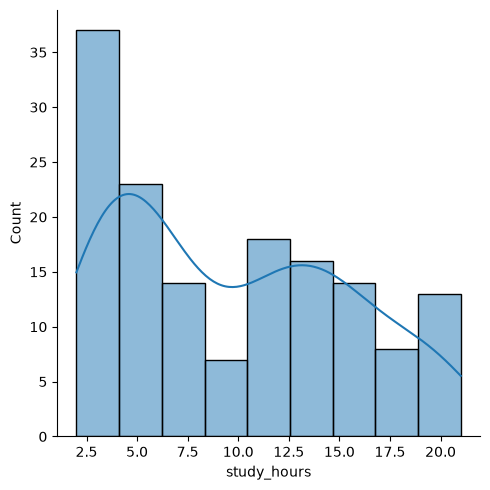

In [72]:
# 2. Distribution Plot (Study Hours ki distribution)
sns.displot(data=data, x='study_hours', kde=True)

<Axes: xlabel='study_hours', ylabel='previous_score'>

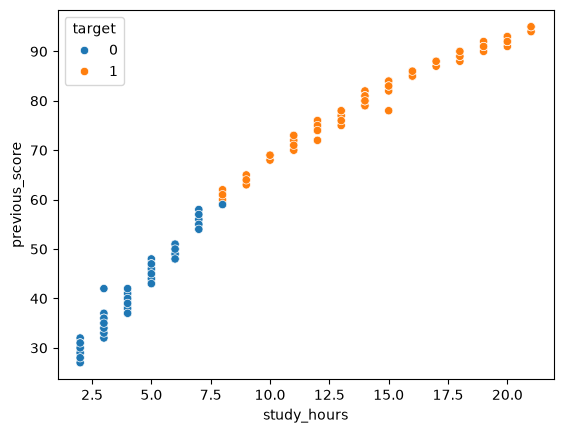

In [23]:
# 1. Scatter Plot (Study Hours vs Previous Score)
sns.scatterplot(data=data, x='study_hours', y='previous_score', hue='target')

In [23]:
x=data.drop(columns=['student_id', 'target'])
y=data['target']

In [24]:
x_train, x_test, y_train, y_test=train_test_split(x, y, test_size=0.2, random_state=42)

In [25]:
model1=KNeighborsClassifier()

In [26]:
model1.fit(x_train, y_train)

KNeighborsClassifier()

In [27]:
y_predict_knn=model1.predict(x_test)

In [28]:
score=accuracy_score(y_test, y_predict)

In [29]:
score_knn=accuracy_score(y_test, y_predict_knn)
score_knn

0.9666666666666667

In [30]:
data.head()

,student_id,gender,age,attendance,study_hours,previous_score,assignments,parent_support,internet_access,target
0,1,1,18,92,15,78,90,1,1,1
1,2,0,19,85,12,72,85,1,1,1
2,3,1,17,60,3,42,50,0,1,0
3,4,0,18,95,18,88,100,1,1,1
4,5,1,20,55,4,38,45,0,0,0


In [44]:
new_student = pd.DataFrame({
    'gender': [0],
    'age': [20],
    'attendance': [85],
    'study_hours': [4],
    'previous_score': [85],
    'assignments': [70],
    'parent_support': [0],
    'internet_access': [0]
})

prediction = model1.predict(new_student)

print("Pass" if prediction[0] == 1 else "Fail")

Pass
